# MBTI Personality Prediction from Social Media Posts

This notebook revisits the original course project (`mbti_original.ipynb`) and fixes three problems:

1. **Label leakage.** Most users mention their own MBTI type in their posts (for example, "as an INFJ..."),
   so a model can read the answer instead of learning from writing style. Type names and cognitive-function
   terms are removed from the text here.
2. **Test set used for tuning.** The original notebook chose parameters by test accuracy. Here, all model
   selection uses 5-fold cross-validation on the training set, and the test set is used once at the end.
3. **Imbalanced classes.** The largest type (INFP) is about 40 times larger than the smallest (ESTJ), so
   accuracy alone is misleading. Macro F1, which weights all 16 types equally, is reported alongside accuracy.

In [ ]:
import re
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, classification_report, confusion_matrix, f1_score)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_validate, train_test_split
from sklearn.naive_bayes import ComplementNB
from sklearn.pipeline import Pipeline
from sklearn.svm import LinearSVC

DATA_PATH = Path('data/mbti.csv')
FIG_DIR = Path('figures')
FIG_DIR.mkdir(exist_ok=True)
SEED = 42
sns.set_theme(style='whitegrid')

## 1. Data

8,675 users, 16 personality types


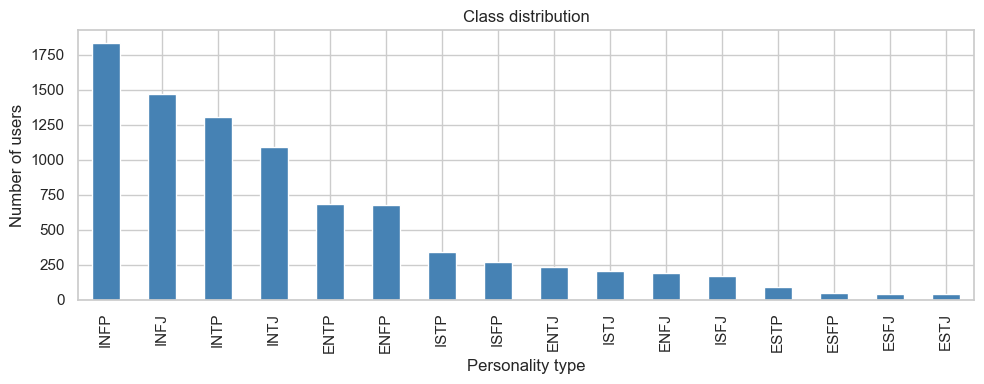

Largest class: INFP (1832), smallest: ESTJ (39)


In [2]:
data = pd.read_csv(DATA_PATH)
print(f'{len(data):,} users, {data.type.nunique()} personality types')

counts = data.type.value_counts()
fig, ax = plt.subplots(figsize=(10, 4))
counts.plot.bar(ax=ax, color='steelblue')
ax.set_xlabel('Personality type')
ax.set_ylabel('Number of users')
ax.set_title('Class distribution')
plt.tight_layout()
fig.savefig(FIG_DIR / 'class_distribution.png', dpi=150)
plt.show()
print(f'Largest class: {counts.index[0]} ({counts.iloc[0]}), smallest: {counts.index[-1]} ({counts.iloc[-1]})')

## 2. Leakage check

How often do users mention an MBTI type, or their own type, in their posts?

In [3]:
TYPES = sorted(data.type.str.lower().unique())
posts_lower = data.posts.str.lower()
mentions_any = posts_lower.str.contains('|'.join(TYPES))
mentions_own = pd.Series([t.lower() in p for t, p in zip(data.type, posts_lower)])
print(f'Users who mention any MBTI type: {mentions_any.mean():.1%}')
print(f'Users who mention their own type: {mentions_own.mean():.1%}')

Users who mention any MBTI type: 96.0%
Users who mention their own type: 90.0%


## 3. Text cleaning

Both versions lowercase the text and remove URLs and non-letter characters. The leak-free version also removes:

- the 16 type names and words that start with them (`infj`, `infjs`, `intjness`, ...)
- partial type patterns with `x` (`inxj`, `xnfp`, ...) and temperament groups (`nf`, `nt`, `sj`, `sp`)
- cognitive-function terms used in MBTI discussions (`ni`, `fe`, `ti-dom`, ...)

In [4]:
URL_RE = re.compile(r'https?://\S+|www\.\S+')
NON_LETTER_RE = re.compile(r'[^a-z\s]')
TYPE_RE = re.compile(r'\b(?:' + '|'.join(TYPES) + r')\w*\b|\b[iex][nsx][tfx][jpx]\w*\b'
                     r'|\b(?:nf|nt|sj|sp|nfs|nts|sjs|sps)\b')
FUNCTION_RE = re.compile(r'\b[nstf][ie](?:\s*(?:dom|aux))?\b')


def clean(text, remove_type_words=True):
    text = URL_RE.sub(' ', text.lower())
    text = NON_LETTER_RE.sub(' ', text)
    if remove_type_words:
        text = TYPE_RE.sub(' ', text)
        text = FUNCTION_RE.sub(' ', text)
    return re.sub(r'\s+', ' ', text).strip()


data['clean_leaky'] = data.posts.map(lambda t: clean(t, remove_type_words=False))
data['clean'] = data.posts.map(clean)

still_mentions = data.clean.str.contains(r'\b(?:' + '|'.join(TYPES) + r')\b')
print(f'Users whose cleaned text still contains a type name: {still_mentions.mean():.1%}')

Users whose cleaned text still contains a type name: 0.0%


## 4. Train/test split

80/20 stratified split. The test set is not used until the final evaluation.

In [5]:
train, test = train_test_split(data, test_size=0.2, stratify=data.type, random_state=SEED)
print(f'Training set: {len(train):,}, test set: {len(test):,}')

Training set: 6,940, test set: 1,735


## 5. Model comparison with cross-validation

Each model is a pipeline of TF-IDF (5,000 features) and a classifier, so the vectorizer is fitted only on the
training folds. Class weights are balanced instead of using SMOTE, which avoids creating synthetic text vectors.

In [6]:
def make_pipeline(clf):
    tfidf = TfidfVectorizer(max_features=5000, stop_words='english',
                            token_pattern=r'\b[a-z]{2,}\b', sublinear_tf=True)
    return Pipeline([('tfidf', tfidf), ('clf', clf)])


candidates = {
    'Most frequent class': DummyClassifier(strategy='most_frequent'),
    'Complement Naive Bayes': ComplementNB(),
    'Logistic Regression': LogisticRegression(max_iter=2000, class_weight='balanced'),
    'Linear SVC': LinearSVC(C=0.1, class_weight='balanced'),
    'Random Forest': RandomForestClassifier(n_estimators=200, class_weight='balanced_subsample',
                                            n_jobs=-1, random_state=SEED),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
rows = []
for name, clf in candidates.items():
    scores = cross_validate(make_pipeline(clf), train.clean, train.type, cv=cv,
                            scoring=['accuracy', 'f1_macro'])
    rows.append({'Model': name,
                 'CV accuracy': scores['test_accuracy'].mean(),
                 'CV macro F1': scores['test_f1_macro'].mean(),
                 'Macro F1 std': scores['test_f1_macro'].std()})

cv_results = pd.DataFrame(rows).sort_values('CV macro F1', ascending=False, ignore_index=True)
cv_results.round(3)

,Model,CV accuracy,CV macro F1,Macro F1 std
0,Logistic Regression,0.341,0.217,0.011
1,Linear SVC,0.324,0.210,0.010
2,Complement Naive Bayes,0.356,0.162,0.009
3,Random Forest,0.252,0.076,0.005
4,Most frequent class,0.211,0.022,0.000


## 6. Hyperparameter tuning

The regularization strength `C` of the two linear models is tuned by cross-validated macro F1.

In [7]:
searches = {
    'Logistic Regression': GridSearchCV(
        make_pipeline(LogisticRegression(max_iter=2000, class_weight='balanced')),
        {'clf__C': [0.3, 1, 3, 10]}, cv=cv, scoring='f1_macro'),
    'Linear SVC': GridSearchCV(
        make_pipeline(LinearSVC(class_weight='balanced')),
        {'clf__C': [0.03, 0.1, 0.3, 1]}, cv=cv, scoring='f1_macro'),
}
for name, search in searches.items():
    search.fit(train.clean, train.type)
    print(f'{name}: best C = {search.best_params_["clf__C"]}, CV macro F1 = {search.best_score_:.3f}')

best_name = max(searches, key=lambda n: searches[n].best_score_)
best_model = searches[best_name].best_estimator_
print(f'\nSelected model: {best_name}')

Logistic Regression: best C = 3, CV macro F1 = 0.219
Linear SVC: best C = 0.1, CV macro F1 = 0.210

Selected model: Logistic Regression


## 7. Final evaluation on the test set

In [8]:
pred = best_model.predict(test.clean)
test_acc = accuracy_score(test.type, pred)
test_f1 = f1_score(test.type, pred, average='macro')
print(f'Test accuracy: {test_acc:.3f}')
print(f'Test macro F1: {test_f1:.3f}\n')
print(classification_report(test.type, pred, zero_division=0))

Test accuracy: 0.360
Test macro F1: 0.241

              precision    recall  f1-score   support

        ENFJ       0.27      0.29      0.28        38
        ENFP       0.28      0.36      0.31       135
        ENTJ       0.14      0.22      0.17        46
        ENTP       0.30      0.34      0.32       137
        ESFJ       0.00      0.00      0.00         9
        ESFP       0.00      0.00      0.00        10
        ESTJ       0.00      0.00      0.00         8
        ESTP       0.09      0.06      0.07        18
        INFJ       0.37      0.32      0.34       294
        INFP       0.51      0.44      0.47       366
        INTJ       0.33      0.34      0.33       218
        INTP       0.42      0.45      0.44       261
        ISFJ       0.24      0.24      0.24        33
        ISFP       0.22      0.30      0.25        54
        ISTJ       0.25      0.17      0.20        41
        ISTP       0.38      0.48      0.42        67

    accuracy                         

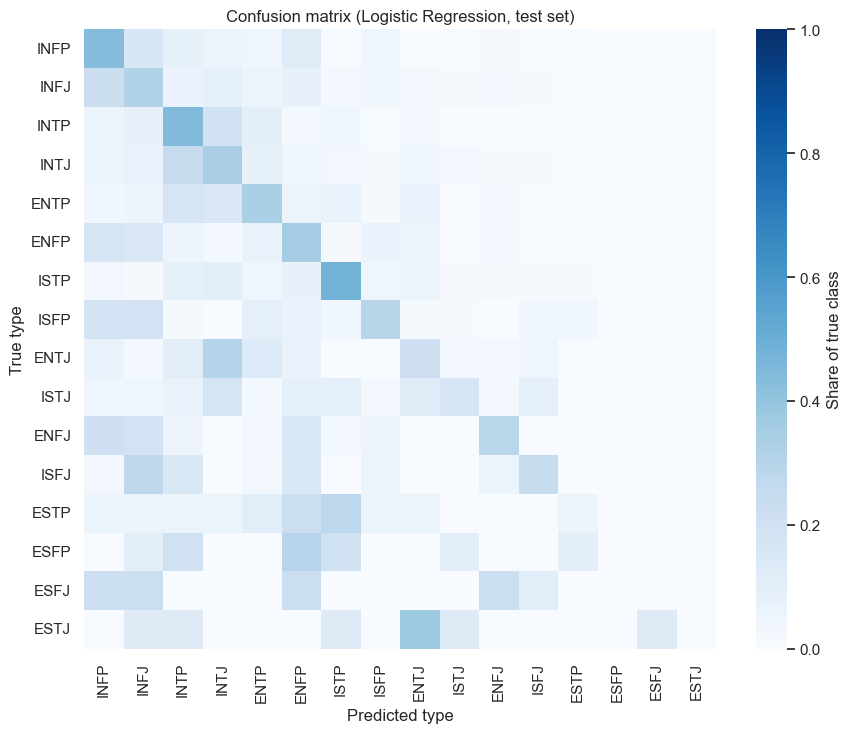

In [9]:
labels = counts.index.tolist()
cm = confusion_matrix(test.type, pred, labels=labels, normalize='true')
fig, ax = plt.subplots(figsize=(9, 7.5))
sns.heatmap(cm, xticklabels=labels, yticklabels=labels, cmap='Blues', vmin=0, vmax=1, ax=ax,
            cbar_kws={'label': 'Share of true class'})
ax.set_xlabel('Predicted type')
ax.set_ylabel('True type')
ax.set_title(f'Confusion matrix ({best_name}, test set)')
plt.tight_layout()
fig.savefig(FIG_DIR / 'confusion_matrix.png', dpi=150)
plt.show()

## 8. How much did leakage inflate the results?

The same pipeline and parameters are trained on text that still contains type names.

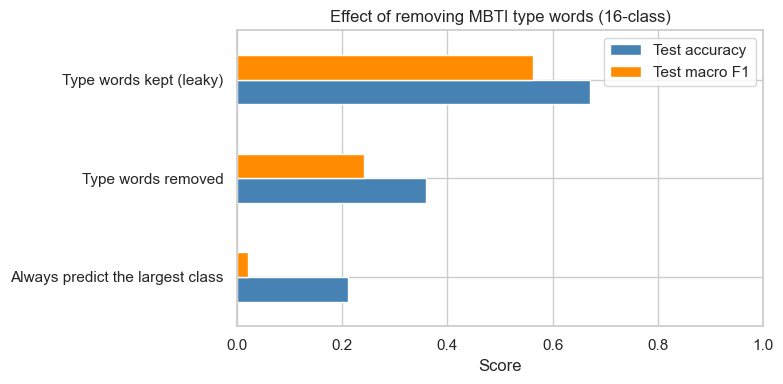

,Setting,Test accuracy,Test macro F1
0,Always predict the largest class,0.211,0.022
1,Type words removed,0.360,0.241
2,Type words kept (leaky),0.671,0.563


In [10]:
leaky_model = clone(best_model).fit(train.clean_leaky, train.type)
leaky_pred = leaky_model.predict(test.clean_leaky)
baseline_pred = np.full(len(test), counts.index[0])

comparison = pd.DataFrame({
    'Setting': ['Always predict the largest class', 'Type words removed', 'Type words kept (leaky)'],
    'Test accuracy': [accuracy_score(test.type, baseline_pred), test_acc,
                      accuracy_score(test.type, leaky_pred)],
    'Test macro F1': [f1_score(test.type, baseline_pred, average='macro'), test_f1,
                      f1_score(test.type, leaky_pred, average='macro')],
})

fig, ax = plt.subplots(figsize=(8, 4))
comparison.set_index('Setting').plot.barh(ax=ax, color=['steelblue', 'darkorange'])
ax.set_xlim(0, 1)
ax.set_xlabel('Score')
ax.set_ylabel('')
ax.set_title('Effect of removing MBTI type words (16-class)')
plt.tight_layout()
fig.savefig(FIG_DIR / 'leakage_comparison.png', dpi=150)
plt.show()
comparison.round(3)

## 9. Predicting each MBTI dimension separately

MBTI types combine four binary dimensions. Predicting each one separately shows which aspects of personality
are reflected in writing. Balanced accuracy is used because the dimensions are imbalanced (for example,
77% of users are introverts).

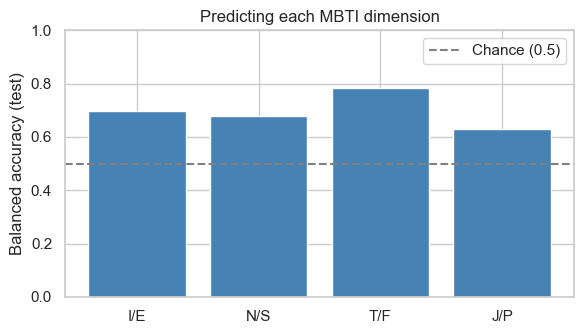

,Dimension,Majority share,Balanced accuracy
0,I/E,0.769,0.696
1,N/S,0.862,0.677
2,T/F,0.541,0.785
3,J/P,0.604,0.629


In [11]:
DIMENSIONS = {'I/E': 0, 'N/S': 1, 'T/F': 2, 'J/P': 3}
rows, dim_models = [], {}
for dim, pos in DIMENSIONS.items():
    y_train = train.type.str[pos]
    y_test = test.type.str[pos]
    model = make_pipeline(LogisticRegression(max_iter=2000, class_weight='balanced'))
    model.fit(train.clean, y_train)
    dim_models[dim] = model
    rows.append({'Dimension': dim,
                 'Majority share': y_test.value_counts(normalize=True).iloc[0],
                 'Balanced accuracy': balanced_accuracy_score(y_test, model.predict(test.clean))})

dimensions = pd.DataFrame(rows)
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.bar(dimensions.Dimension, dimensions['Balanced accuracy'], color='steelblue')
ax.axhline(0.5, color='gray', linestyle='--', label='Chance (0.5)')
ax.set_ylim(0, 1)
ax.set_ylabel('Balanced accuracy (test)')
ax.set_title('Predicting each MBTI dimension')
ax.legend()
plt.tight_layout()
fig.savefig(FIG_DIR / 'dimensions.png', dpi=150)
plt.show()
dimensions.round(3)

## 10. Most informative words for each dimension

The largest logistic regression coefficients show which words push the prediction toward each side.

In [12]:
rows = []
for dim, model in dim_models.items():
    words = model.named_steps['tfidf'].get_feature_names_out()
    clf = model.named_steps['clf']
    order = np.argsort(clf.coef_[0])
    first, second = clf.classes_
    rows.append({'Dimension': dim,
                 'Words toward first letter': f"{first}: " + ', '.join(words[order[:8]]),
                 'Words toward second letter': f"{second}: " + ', '.join(words[order[-8:][::-1]])})

pd.set_option('display.max_colwidth', None)
pd.DataFrame(rows)

,Dimension,Words toward first letter,Words toward second letter
0,I/E,"E: sx, fun, bored, crazy, guys, awesome, super, xd","I: games, family, quiet, wish, anime, nature, lyrics, listening"
1,N/S,"N: world, ideas, dark, human, universe, books, fact, heart","S: rant, type, rave, inferior, fun, mbti, car, teddy"
2,T/F,"F: feel, love, values, feeling, beautiful, heart, xd, happy","T: female, boring, knowledge, fucking, stupid, bored, shit, forum"
3,J/P,"J: plan, cold, intuition, help, dear, plans, hsp, door","P: lazy, fuck, pretty, love, theories, really, weed, fun"


## 11. Conclusions

- **Leakage was the main source of the original accuracy.** 90% of users mention their own type. With the same
  model, removing type words drops test accuracy from 67.1% to 36.0% and macro F1 from 0.563 to 0.241.
- **Writing style still carries some signal.** The leak-free model is well above the 21.1% majority baseline,
  and Logistic Regression is the best of the models compared (CV macro F1 0.219 after tuning).
- **Rare types are hardest.** ESFJ, ESFP, and ESTJ have fewer than 10 test users each and are never predicted
  correctly, while INFP, INTP, and ISTP reach F1 above 0.4.
- **Thinking vs. Feeling is the most predictable dimension** (balanced accuracy 0.785), followed by I/E (0.696),
  N/S (0.677), and J/P (0.629). Feeling types use words like *feel*, *love*, and *values*; introverts mention
  *games*, *family*, *quiet*, and *nature*.
- **Some MBTI vocabulary remains** (for example *intuition*, *inferior*, *mbti*, *sx*), so a small amount of
  forum-specific signal is still present after cleaning.